# Case Study 30 — "92% Resolved by AI": Resolution Rate Against Reality, CSAT That Only 9% of Customers Give, and Where to Escalate

**Priority:** ★ Optional · **Reference:** Case Study 30 — *PhonePe: AI-first customer support (intent classification + LLM summaries + knowledge retrieval)* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Customer Support, Product (support automation), Risk/Grievance Redressal, Finance
**Data:** ⚠️ **SYNTHETIC** (D-30-01). Support data are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs30_support_automation_resolution.ipynb`

## 0. Executive Summary for Business

*(Synthetic contacts with a randomised human-only holdout and a self-selected CSAT survey; PhonePe disclosed only "over 92%" resolved by AI, CSAT 70% and one agent per 20 million transactions. Written after the analysis.)*

- **The question:** is "92% resolved by AI" real, and what does it do to customers the bot cannot help?
- **"Resolved" by the bot is not "fixed".** In the simulation the bot **closes 87.6%** of tickets, close to the documented 92%, but only **80.2% are truly resolved** (the customer does not come back within 7 days). A **randomised 5% human-only holdout** resolves **85.9%**. AI-first is **5.7 pp worse** (CI −6.6 to −4.8) and **fails the 3 pp non-inferiority test**. It is also far faster: **2.5 vs 10.1 minutes** handling and **0.8 vs 9.0 minutes** wait.
- **The damage is concentrated in high-stakes issues.** For fraud complaints the bot closes 76% of tickets but only **35%** of those stay closed (human-only: 80%). Wrong-recipient transfers: 38% (human 83%); merchant disputes 53%; blocked accounts 63%. For routine issues (refund status, transaction history, payment debited-but-failed) the bot matches or beats humans.
- **CSAT tells a flattering story and needs correcting.** Only **8.9%** of customers answer, and unhappy customers answer more (a customer who had to re-contact is 19% more likely to respond). Raw top-2-box CSAT among responders is 61.9%. Weighting for non-response gives **64.0%**, closer to the true 65.5%. AI-first CSAT (65%) looks better than human-only (46%) *because speed delights customers*, even though true resolution is worse, which is why CSAT alone must never be the success metric. Across issue types CSAT tracks true resolution closely (Spearman +0.96).
- **The bot treats languages unequally:** adjusted odds of true resolution for **regional-language** customers are **0.74×** English (CI 0.70–0.77); intent accuracy 88.7% vs 93.2%.
- **The fix is cheap: ring-fence high-stakes issues.** Never letting the bot auto-close fraud, wrong-recipient, blocked-account and merchant-dispute tickets lifts true resolution from **80% to 84%**, cuts false closures by a third, and cuts expected cost per contact from **₹87 to ₹34** (human-only: ₹78). That is **≈ ₹160 crore/month cheaper than AI as run** at 3 crore contacts (illustrative cost weights).
- **I recommend:**
  - Route high-stakes issues to humans.
  - Replace "resolution rate" with 7-day true resolution as the headline.
  - Report CSAT only with a non-response correction.
  - Keep a 2–5% human-only holdout.
  - Invest in regional-language intent accuracy.

## 1. The Problem in Simple English

A payments app handles billions of transactions a month, so support volume grows with it. PhonePe made AI the **first line of support**: it works out what the customer's problem is (intent classification), reads their transaction and ticket history, finds the right help article, and either resolves the issue or passes it to a human. It reports "**over 92%**" of queries resolved by AI, "**one support agent for every 20 million transactions**", and **CSAT of 70%**.

Three questions that every support leader should ask of such numbers:
1. **"Resolved" by whose definition?** The bot closing a ticket is not the same as the customer's problem being fixed. A true test is that the customer **does not come back** about the same issue.
2. **CSAT from whom?** Only a small share of customers rate. If unhappy customers are more likely to answer (or to skip), the score is biased.
3. **What is the cost to customers the bot cannot help?** A fraud complaint or a debited-but-failed payment handled badly is a serious harm, not a statistic.

This notebook measures all three, uses a **randomised human-only holdout** as the benchmark, and shows how to choose when the bot should escalate.

## 2. Reference from the Case File

### (a) What PhonePe did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "Support volume grows with billions of transactions a month. Hiring agents in proportion is not sustainable." |
| Question | "What is the user's issue, and can it be resolved automatically using their transaction and ticket context?" |
| Data | Transaction history linked to the query; ticket history; a knowledge base |
| Approach | "Intent classification → LLM summaries of transaction and ticket history → knowledge-base matching → multilingual chatbot or voicebot → human escalation" |
| ML / metrics | Intent classifiers, LLMs; specifics ND; **AI resolution rate, CSAT, handling time** |
| Impact | "Over **92%**" of queries resolved by AI; "one support agent for every **20 million** transactions"; CSAT **70%**; 30–50 seconds saved per interaction |
| Lesson | "Report **resolution rate together with CSAT**. Automation that resolves tickets but annoys users is not a win." |

**Source:** PhonePe engineering blog / press coverage (link in the reference file).

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 120,000 contacts over 8 weeks, 12 issue types (routine ones such as "refund status"; high-stakes ones such as "fraud complaint", "wrong-recipient transfer"), 4 languages. **95% AI-first, a random 5% human-only holdout.** Per contact: intent prediction and confidence, whether the bot **closed** it, whether it escalated, handling time, whether the customer **re-contacted within 7 days** about the same issue, and CSAT (1–5) given by only ≈ 9% of customers. |
| Statistics added | Intent accuracy by language (Wilson, χ²); **claimed vs true resolution** (bot-closed vs 7-day non-recontact) by intent; randomised **AI vs holdout** comparison on true resolution, recontact, time (two-proportion z, Newcombe CI, Mann–Whitney); **CSAT non-response bias** and inverse-probability-weighted CSAT; resolution–CSAT trade-off by intent; **escalation threshold** chosen on a cost curve with Clopper–Pearson bound on harm; per-language fairness; power |

### (c) How the industry uses this

AI-first support is now the norm in Indian fintech (PhonePe, Paytm, Cred, Razorpay, banks' chat assistants), with RBI's Integrated Ombudsman and grievance-redressal rules making **mis-closed complaints** a compliance issue, not only an experience issue. Containment/deflection rate is the number leaders usually quote. Mature teams measure **resolution** (no repeat contact), **CSAT with a non-response correction**, and **escalation quality**.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Is AI-first support really resolving customers' problems, and where must a human step in? |
| Analytical | What are the claimed and true resolution rates, how do they compare with human-only support, and how reliable is CSAT as a quality signal? |

**Hypotheses**
- **H1 (claim vs reality):** H0: among bot-closed tickets, the 7-day non-recontact rate equals the human-only holdout's.
- **H2 (randomised):** H0: true resolution (no recontact) is the same for AI-first and human-only (two-proportion; non-inferiority margin 3 pp).
- **H3 (CSAT bias):** H0: responders and non-responders have the same distribution of (latent) satisfaction; an IPW-corrected CSAT equals the raw responder CSAT.
- **H4 (escalation):** a confidence threshold exists at which harm from wrongly closed high-stakes tickets ≤ 1% (Clopper–Pearson).

**Primary metric:** **true resolution** (no 7-day recontact), alongside **CSAT (weighted)** and **handling time**. **Guardrail:** wrongly closed high-stakes tickets (fraud, wrong recipient, blocked account).

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint, confint_proportions_2indep, proportions_ztest
from statsmodels.stats.multitest import multipletests
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public support-ticket data with intents, resolution and CSAT | **None** for Indian fintech. Public customer-support sets (e.g., Twitter customer support, Kaggle ticket datasets) lack recontact and CSAT linkage. |
| **Decision** | Synthetic contacts with a randomised human-only holdout and a biased survey (D-30-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs30.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 30 (PhonePe-style AI-first customer support: intent, resolution and CSAT)
==============================================================================================================
THIS DATA IS SYNTHETIC. Support tickets, chats and CSAT surveys are confidential.

120,000 support contacts over 8 weeks across 12 issue types (some routine, some high-stakes such as fraud
complaints or wrong-recipient transfers). 95% of customers are served AI-first (bot attempts, escalates to a
human when it is unsure or the intent is not automatable); a RANDOM 5% HOLDOUT is served human-only.
Recorded per contact: language, true intent, the bot's predicted intent and confidence, whether the bot CLAIMED
resolution (closed the ticket), whether it was ESCALATED, handling time, whether the customer RE-CONTACTED on the
same issue within 7 days (the real test of resolution), and a CSAT rating (1-5) that only ~12% of customers give.
Survey response depends on experience (unhappy and very happy customers respond more), so CSAT among responders
is a BIASED picture. A latent satisfaction drives the rating.
The bot over-claims resolution on a few intents (it closes with a generic article), which is the classic
"resolution rate vs reality" problem.

Calibration anchors (reference file, Case Study 30): "over 92%" of queries resolved by AI; "one support agent for
every 20 million transactions"; CSAT 70%; 30-50 seconds saved per interaction; AI is first line, agents escalate.
Rates are our assumptions (decision.md D-30-02). Hidden truth columns start with "_".

Output: data/cs30/contacts.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
INTENTS = ["payment_failed_debited", "refund_status", "kyc_update", "app_login_issue", "recharge_bill_failed", "transaction_history", "wrong_recipient_transfer",
           "fraud_complaint", "account_blocked", "autopay_mandate", "cashback_missing", "merchant_dispute"]
P = np.array([0.18, 0.12, 0.08, 0.10, 0.10, 0.07, 0.04, 0.03, 0.05, 0.07, 0.10, 0.06])
AUTOMATABLE = {"payment_failed_debited": 0.85, "refund_status": 0.95, "kyc_update": 0.80, "app_login_issue": 0.90, "recharge_bill_failed": 0.88, "transaction_history": 0.98,
               "wrong_recipient_transfer": 0.10, "fraud_complaint": 0.05, "account_blocked": 0.30, "autopay_mandate": 0.85, "cashback_missing": 0.55, "merchant_dispute": 0.25}   # P(bot CAN truly fix)
OVERCLAIM = {"cashback_missing": 0.55, "merchant_dispute": 0.50, "account_blocked": 0.35, "payment_failed_debited": 0.10}                                                      # P(bot closes anyway when it cannot fix)


def generate(seed=SEED, n=120_000):
    rng = np.random.default_rng(seed)
    week = rng.integers(1, 9, n); lang = rng.choice(["english", "hindi", "hinglish", "regional"], n, p=[0.28, 0.32, 0.28, 0.12])
    ti = rng.choice(len(INTENTS), n, p=P); intent = np.array(INTENTS)[ti]
    holdout = (rng.random(n) < 0.05).astype(int)
    lang_pen = pd.Series(lang).map({"english": 0.0, "hindi": 0.35, "hinglish": 0.20, "regional": 0.70}).values
    # intent classification
    conf = np.clip(rng.beta(7, 2.2, n) - 0.16 * lang_pen + rng.normal(0, 0.03, n), 0.05, 0.99); correct = rng.random(n) < np.clip(0.55 + 0.5 * conf, 0.3, 0.995)
    pred = np.where(correct, ti, rng.integers(0, len(INTENTS), n))
    can_fix = rng.random(n) < pd.Series(intent).map(AUTOMATABLE).values * np.where(lang_pen > 0.5, 0.88, 1.0)
    over = rng.random(n) < pd.Series(intent).map(OVERCLAIM).fillna(0.75).values
    ai = holdout == 0
    attempt_close = ai & (conf >= 0.20) & (can_fix | over)                                    # bot closes the ticket
    escalated = ai & ~attempt_close
    true_resolved_bot = attempt_close & can_fix & correct
    # human outcomes
    human_fix = rng.random(n) < expit(1.9 - 0.35 * pd.Series(intent).isin(["fraud_complaint", "wrong_recipient_transfer", "merchant_dispute"]).values + rng.normal(0, 0.3, n))
    handled_by_human = (~ai) | escalated
    resolved = np.where(attempt_close, true_resolved_bot | (rng.random(n) < 0.04), human_fix)
    recontact = ~resolved & (rng.random(n) < 0.72) | (resolved & (rng.random(n) < 0.04))
    minutes = np.where(attempt_close, np.round(rng.exponential(0.7, n) + 0.2, 2), np.where(escalated, np.round(np.exp(rng.normal(np.log(10.5), 0.5, n)) + 1.5, 2), np.round(np.exp(rng.normal(np.log(9.0), 0.5, n)), 2)))
    wait = np.where(attempt_close, 0.1, np.where(escalated, np.round(rng.exponential(6, n), 1), np.round(rng.exponential(9, n), 1)))
    # latent satisfaction -> CSAT rating; survey response depends on experience
    sat = 0.9 * np.where(resolved, 1.0, -1.1) - 0.04 * np.minimum(minutes, 30) - 0.03 * wait + 0.3 * attempt_close * resolved - 0.45 * (attempt_close & ~resolved) + rng.normal(0, 0.8, n) + 3.4
    csat = np.clip(np.round(sat), 1, 5)
    p_resp = expit(-2.5 + 0.55 * (csat <= 2) + 0.35 * (csat == 5) - 0.1 * attempt_close)
    responded = rng.random(n) < p_resp
    df = pd.DataFrame({"contact_id": [f"SC{i:06d}" for i in range(n)], "week": week, "language": lang, "served_ai_first": ai.astype(int), "predicted_intent": np.array(INTENTS)[pred],
                       "intent_confidence": conf.round(3), "bot_closed": attempt_close.astype(int), "escalated_to_human": escalated.astype(int), "handling_minutes": minutes, "wait_minutes": wait,
                       "recontact_7d": recontact.astype(int), "csat": np.where(responded, csat, np.nan), "_intent": intent, "_resolved": resolved.astype(int), "_csat_latent": csat})
    df.loc[df.sample(n=500, random_state=seed).index, "handling_minutes"] = np.nan                  # timer lost on abrupt chat close
    df = pd.concat([df, df.sample(n=700, random_state=seed + 1)], ignore_index=True)
    df.loc[df.sample(n=40, random_state=seed + 2).index, "csat"] = 0                                 # survey widget returns 0 (invalid rating)
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs30"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs30", "contacts.csv.gz"), index=False)
    dd = d.drop_duplicates("contact_id"); a = dd[dd.served_ai_first == 1]
    print(len(dd), "contacts | bot-closed", a.bot_closed.mean().round(3), "| escalated", a.escalated_to_human.mean().round(3))
    print("true resolution: AI-first", a._resolved.mean().round(3), "holdout", dd[dd.served_ai_first == 0]._resolved.mean().round(3), "| bot-closed true res", a[a.bot_closed == 1]._resolved.mean().round(3))
    print("recontact", dd.groupby("served_ai_first").recontact_7d.mean().round(3).to_dict(), "| CSAT>=4 among responders", (dd[dd.csat.between(1, 5)].csat >= 4).mean().round(3), "response rate", dd.csat.notna().mean().round(3))
    print("handling min", dd.groupby("served_ai_first").handling_minutes.mean().round(2).to_dict())

Overwriting data/generate_cs30.py


In [3]:
os.makedirs("data/cs30", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs30 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED); raw.to_csv("data/cs30/contacts.csv.gz", index=False)
print(f"{len(raw):,} contact rows | {raw.contact_id.nunique():,} unique contacts")
raw.drop(columns=["_intent", "_resolved", "_csat_latent"]).sample(3, random_state=SEED).T

120,700 contact rows | 120,000 unique contacts


,5823,39085,38683
contact_id,SC005823,SC039085,SC038683
week,2,6,5
language,hinglish,english,hinglish
served_ai_first,1,1,1
predicted_intent,payment_failed_debited,refund_status,transaction_history
intent_confidence,0.6130,0.8510,0.6790
bot_closed,1,1,1
escalated_to_human,0,0,0
handling_minutes,1.6400,1.2200,0.3700
wait_minutes,0.1000,0.1000,0.1000


| Parameter | Value | Basis |
|---|---|---|
| Contacts | 120,000 over 8 weeks; 12 issue types; languages English 28% / Hindi 32% / Hinglish 28% / regional 12% | Our assumption |
| Design | 95% AI-first; **random 5% human-only holdout** | Our design (what a careful team keeps) |
| Bot behaviour | Predicts intent with confidence; closes the ticket when confidence ≥ 0.2 and it can fix the issue **or** over-claims (closes with a generic article); regional-language accuracy is lower | **Documented** pipeline; over-claiming is our assumption |
| Resolution truth | Bot truly fixes routine issues (refund status 95%, history 98%) and rarely the hard ones (fraud 5%, wrong recipient 10%); humans fix ≈ 85% | Our assumption |
| Recontact | 72% of unresolved customers contact again within 7 days (4% of resolved ones do) | Our assumption |
| CSAT | Latent satisfaction → rating 1–5; **only ≈ 9% respond**; unhappy (1–2) and delighted (5) respond more | Typical survey behaviour |
| DQ issues | 700 duplicate rows; 500 lost handling timers; 40 CSAT values of 0 (invalid) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("contact_id, week, language", "Contact, week, language"), ("served_ai_first", "1 = AI-first (95%); 0 = random human-only holdout (5%)"), ("predicted_intent, intent_confidence", "Bot's intent and confidence"),
    ("bot_closed, escalated_to_human", "Bot closed the ticket / handed it to a human"), ("handling_minutes, wait_minutes", "Handling time; wait before help"),
    ("recontact_7d", "Customer contacted again about the same issue within 7 days (true resolution = 0)"), ("csat", "1–5 rating if the customer responded (≈ 9%); blank otherwise; 0 = invalid"),
    ("_intent, _resolved, _csat_latent", "HIDDEN true intent, true resolution, latent satisfaction"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs30/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"contact_id, week, language","Contact, week, language"
1,served_ai_first,1 = AI-first (95%); 0 = random human-only hold...
2,"predicted_intent, intent_confidence",Bot's intent and confidence
3,"bot_closed, escalated_to_human",Bot closed the ticket / handed it to a human
4,"handling_minutes, wait_minutes",Handling time; wait before help
5,recontact_7d,Customer contacted again about the same issue ...
6,csat,1–5 rating if the customer responded (≈ 9%); b...
7,"_intent, _resolved, _csat_latent","HIDDEN true intent, true resolution, latent sa..."


## 5. Data Quality Checks

In [5]:
checks = {"duplicate contacts": int(raw.contact_id.duplicated().sum()), "handling time missing (timer lost)": int(raw.drop_duplicates("contact_id").handling_minutes.isna().sum()),
          "CSAT = 0 (invalid)": int((raw.csat == 0).sum()), "bot-closed but also escalated": int(((raw.bot_closed == 1) & (raw.escalated_to_human == 1)).sum())}
print(pd.Series(checks, name="rows").to_string())
df = raw.drop_duplicates("contact_id").copy(); df.loc[df.csat == 0, "csat"] = np.nan
df["true_resolved"] = 1 - df.recontact_7d; df["intent"] = df._intent
df["high_stakes"] = df.intent.isin(["fraud_complaint", "wrong_recipient_transfer", "account_blocked", "merchant_dispute"]).astype(int)
ai, ho = df[df.served_ai_first == 1].copy(), df[df.served_ai_first == 0].copy()
print(f"\nClean: {len(df):,} contacts | AI-first {len(ai):,} | human-only holdout {len(ho):,} ({len(ho) / len(df):.1%}) | CSAT responses {df.csat.notna().sum():,} ({df.csat.notna().mean():.1%})")

duplicate contacts                    700
handling time missing (timer lost)    500
CSAT = 0 (invalid)                     40
bot-closed but also escalated           0



Clean: 120,000 contacts | AI-first 113,980 | human-only holdout 6,020 (5.0%) | CSAT responses 10,686 (8.9%)


**Observation:** we removed **700 duplicate contacts** and set **40 invalid CSAT ratings of 0** to missing (a 0 on a 1–5 scale would drag the score down). **500 contacts have no handling time** (timer lost when a chat closed abruptly); they are excluded only from time averages. Clean: **120,000 contacts**; **113,980 AI-first** and **6,020 in the human-only holdout (5.0%)**. **CSAT responses: 10,686 (8.9%)**.

## 6. Exploratory Data Analysis

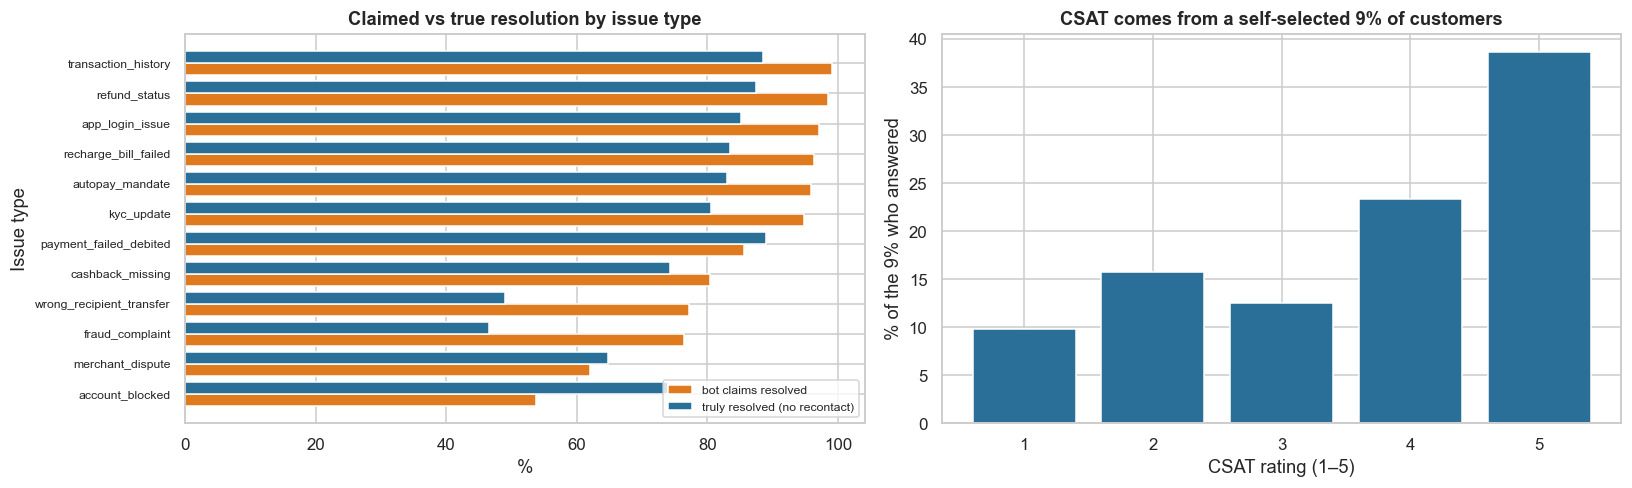

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
g = ai.groupby("intent").agg(bot_closed=("bot_closed", "mean"), true=("true_resolved", "mean"), n=("contact_id", "size")).sort_values("bot_closed")
y = np.arange(len(g)); axes[0].barh(y - 0.2, g.bot_closed * 100, 0.4, color="#e07a1f", label="bot claims resolved"); axes[0].barh(y + 0.2, g.true * 100, 0.4, color="#2a6f97", label="truly resolved (no recontact)")
axes[0].set_yticks(y); axes[0].set_yticklabels(g.index, fontsize=8); axes[0].set_xlabel("%"); axes[0].set_ylabel("Issue type"); axes[0].set_title("Claimed vs true resolution by issue type"); axes[0].legend(fontsize=8)
csat = df.csat.dropna().astype(int).value_counts(normalize=True).sort_index() * 100; axes[1].bar(csat.index.astype(str), csat.values, color="#2a6f97"); axes[1].set_xlabel("CSAT rating (1–5)"); axes[1].set_ylabel("% of the 9% who answered")
axes[1].set_title("CSAT comes from a self-selected 9% of customers")
plt.tight_layout(); plt.show()

**Takeaway:** **left:** for routine issues (refund status, transaction history, recharge, login) the bot's claimed resolution and the true resolution are close. For fraud, wrong-recipient, merchant disputes and blocked accounts there is a **big gap**: the bot closes 54–77% of these tickets, yet far fewer stay resolved. **Right:** CSAT ratings come only from a self-selected 9% of customers, with more 1s and 5s than a random sample would give (people with extreme experiences answer).

## 7. Statistical Analysis (core section)

### 7.1 Intent classification: accuracy and who it fails

Accuracy of the bot's predicted intent against the true intent (from the hidden truth; in practice a labelled sample), overall and **by language**, with Wilson CIs and a χ² test.

In [7]:
ai["intent_ok"] = (ai.predicted_intent == ai.intent).astype(int)
la = ai.groupby("language").intent_ok.agg(["mean", "sum", "size"]); ci = [proportion_confint(r["sum"], r["size"], method="wilson") for _, r in la.iterrows()]; la["CI low"], la["CI high"] = [c[0] for c in ci], [c[1] for c in ci]
c2 = stats.chi2_contingency(pd.crosstab(ai.language, ai.intent_ok)); lo, hi = proportion_confint(ai.intent_ok.sum(), len(ai), method="wilson")
print(f"Overall intent accuracy {ai.intent_ok.mean():.1%} (Wilson {lo:.1%}–{hi:.1%}) | by language χ² = {c2[0]:.0f}, p = {c2[1]:.2g} | mean confidence {ai.intent_confidence.mean():.2f}")
la.sort_values("mean").round(4)

Overall intent accuracy 91.7% (Wilson 91.5%–91.9%) | by language χ² = 281, p = 1.3e-60 | mean confidence 0.72


,mean,sum,size,CI low,CI high
language,,,,,
regional,0.8873,12229,13782,0.8819,0.8925
hindi,0.9112,33171,36405,0.9082,0.9140
hinglish,0.9217,29291,31778,0.9187,0.9246
english,0.9321,29840,32015,0.9293,0.9348


**(c)/(f) Observation:** the bot predicts the right intent **91.7%** of the time (Wilson 91.5–91.9%), but accuracy varies by language (χ² = 281, p ≈ 1e-60): **English 93.2%, Hinglish 92.2%, Hindi 91.1%, regional languages 88.7%**. **(f) Business meaning:** intent accuracy is high overall, yet one in nine regional-language customers is mis-understood, which feeds directly into unequal outcomes (7.7).

### 7.2 The headline: claimed resolution vs true resolution (randomised benchmark)

**(a)** Three numbers for the AI-first group:
- **Bot-closed rate** ("containment", what the bot claims).
- **True resolution:** no recontact within 7 days.
- **True resolution among bot-closed tickets.**

We compare true resolution of AI-first with the **randomised human-only holdout** (two-proportion z, Newcombe CI), with a **non-inferiority margin of 3 pp**. We also compare recontact, handling time and wait (Mann–Whitney).

In [8]:
def prop_row(name, x1, n1, x0, n0):
    lo, hi = confint_proportions_2indep(x1, n1, x0, n0, method="newcomb"); z, p = proportions_ztest([x1, x0], [n1, n0]); return (name, x1 / n1, x0 / n0, (x1 / n1 - x0 / n0) * 100, lo * 100, hi * 100, p)
bc = ai[ai.bot_closed == 1]
print(f"AI-first: bot claims {ai.bot_closed.mean():.1%} resolved | truly resolved {ai.true_resolved.mean():.1%} | among bot-closed tickets only {bc.true_resolved.mean():.1%} | human-only holdout truly resolved {ho.true_resolved.mean():.1%}")
rows = [prop_row("true resolution: AI-first vs human-only", ai.true_resolved.sum(), len(ai), ho.true_resolved.sum(), len(ho)),
        prop_row("true resolution: bot-closed tickets vs human-only", bc.true_resolved.sum(), len(bc), ho.true_resolved.sum(), len(ho)),
        prop_row("7-day recontact: AI-first vs human-only", ai.recontact_7d.sum(), len(ai), ho.recontact_7d.sum(), len(ho))]
cmp_ = pd.DataFrame(rows, columns=["comparison", "AI-first", "human-only", "diff (pp)", "CI low", "CI high", "p"]).set_index("comparison")
tt = []
for c_, lab in (("handling_minutes", "handling minutes"), ("wait_minutes", "wait minutes")):
    a_, h_ = ai[c_].dropna(), ho[c_].dropna(); mw = stats.mannwhitneyu(a_, h_); tt.append((lab, a_.mean(), h_.mean(), (a_.mean() / h_.mean() - 1), mw.pvalue))
tt = pd.DataFrame(tt, columns=["metric", "AI-first mean", "human-only mean", "relative change", "Mann–Whitney p"]).set_index("metric")
ni = cmp_.iloc[0]; print(f"Non-inferiority (margin −3 pp) of AI-first on true resolution: lower CI bound {ni['CI low']:+.1f} pp → {'non-inferior' if ni['CI low'] > -3 else 'NOT non-inferior'}")
display(cmp_.round(4)); tt.round(4)

AI-first: bot claims 87.6% resolved | truly resolved 80.2% | among bot-closed tickets only 79.4% | human-only holdout truly resolved 85.9%
Non-inferiority (margin −3 pp) of AI-first on true resolution: lower CI bound -6.6 pp → NOT non-inferior


,AI-first,human-only,diff (pp),CI low,CI high,p
comparison,,,,,,
true resolution: AI-first vs human-only,0.8022,0.8591,-5.6899,-6.5767,-4.7593,0.0000
true resolution: bot-closed tickets vs human-only,0.7938,0.8591,-6.5332,-7.4254,-5.5975,0.0000
7-day recontact: AI-first vs human-only,0.1978,0.1409,5.6899,4.7593,6.5767,0.0000


,AI-first mean,human-only mean,relative change,Mann–Whitney p
metric,,,,
handling minutes,2.4560,10.1280,-0.7575,0.0000
wait minutes,0.8313,9.0203,-0.9078,0.0000


**(c)/(f) Observation:** - **The bot claims 87.6% resolved** (documented "over 92%"), **but 80.2% of AI-first contacts are truly resolved**; among bot-closed tickets only **79.4%** are. The **human-only holdout resolves 85.9%**.
- **True resolution is 5.7 pp lower with AI-first** (CI −6.6 to −4.8, p < 0.0001): **not non-inferior at a 3 pp margin**. Recontact is 19.8% vs 14.1%.
- **But AI is vastly faster:** handling time **2.5 vs 10.1 minutes (−76%)**, wait **0.8 vs 9.0 minutes (−91%)**.
- **(f) Business meaning:** the headline "92% resolved" confuses *closed* with *fixed*. A fair benchmark (the holdout) shows a real quality cost, offset by huge speed gains. Leaders need to decide that trade-off with eyes open, issue type by issue (7.3).

### 7.3 Where does the bot over-claim? By issue type

For each issue type: bot-closed rate, **true resolution among bot-closed tickets**, the **false-closure rate** (closed but customer came back), and the human-only holdout's true resolution for the same type, with a one-sided test (AI-closed vs holdout, Holm across 12 types).

In [9]:
rows = []
for it, g in ai.groupby("intent"):
    b = g[g.bot_closed == 1]; h = ho[ho.intent == it]
    if len(b) < 30 or len(h) < 20: continue
    z, p = proportions_ztest([b.true_resolved.sum(), h.true_resolved.sum()], [len(b), len(h)], alternative="smaller")
    rows.append((it, len(g), g.bot_closed.mean(), len(b), b.true_resolved.mean(), 1 - b.true_resolved.mean(), h.true_resolved.mean(), len(h), p))
oc = pd.DataFrame(rows, columns=["issue type", "AI-first contacts", "bot-closed rate", "bot-closed tickets", "true resolution (closed)", "false-closure rate", "human-only resolution", "holdout n", "p (AI < human)"]).set_index("issue type")
oc["p_holm"] = multipletests(oc["p (AI < human)"], method="holm")[1]; oc.sort_values("false-closure rate", ascending=False).round(4)

,AI-first contacts,bot-closed rate,bot-closed tickets,true resolution (closed),false-closure rate,human-only resolution,holdout n,p (AI < human),p_holm
issue type,,,,,,,,,
fraud_complaint,3366,0.7638,2571,0.3497,0.6503,0.8022,182,0.0000,0.0000
wrong_recipient_transfer,4516,0.7713,3483,0.3844,0.6156,0.8259,270,0.0000,0.0000
merchant_dispute,6805,0.6200,4219,0.5271,0.4729,0.8397,343,0.0000,0.0000
account_blocked,5807,0.5381,3125,0.6294,0.3706,0.8522,291,0.0000,0.0000
cashback_missing,11395,0.8043,9165,0.7136,0.2864,0.8725,604,0.0000,0.0000
kyc_update,9074,0.9478,8600,0.8016,0.1984,0.8706,487,0.0001,0.0006
autopay_mandate,7974,0.9587,7645,0.8277,0.1723,0.8626,422,0.0320,0.1920
recharge_bill_failed,11398,0.9630,10976,0.8333,0.1667,0.8529,605,0.1032,0.5160
app_login_issue,11381,0.9706,11046,0.8506,0.1494,0.8683,638,0.1105,0.5160


**Observation:** the quality gap is almost entirely in the **hard, high-stakes issues**:
- **Fraud complaints:** the bot closes 76%, but only **35%** of closed tickets stay resolved (false-closure rate 65%), vs 80% for humans.
- **Wrong-recipient transfers:** 38% vs 83% for humans (false-closure 62%).
- **Merchant disputes:** 53% vs 84%; **blocked accounts:** 63% vs 85%; **cashback missing:** 71% vs 87%.
- All significantly worse than humans (Holm p < 0.001), as are **KYC updates** (80% vs 87%).
- **Routine issues:** recharge/bill failure, app login, refund status, transaction history and "payment debited but failed" are statistically **no worse than humans** (several slightly better).

**Business meaning:** AI-first works for routine issues and fails where the stakes are highest, exactly where RBI grievance-redressal rules and customer harm concentrate.

### 7.4 CSAT: who answers, and what does the score really say?

**(a)** Only ≈ 9% of customers answer. We (i) model **who responds** (logistic on language, issue type, bot-closed, resolved, wait), (ii) compute raw CSAT (top-2-box share, 4–5) among responders, (iii) reweight responders by **inverse probability of response** using only information available for everyone (language, issue type, bot-closed, wait, and handling time, not the unobservable true satisfaction), and (iv) compare with the **true latent top-2-box** share (known only in simulation). We also show CSAT for AI-first vs holdout, raw and weighted, with bootstrap CIs.

In [10]:
d = df.copy(); d["resp"] = d.csat.notna().astype(int); d["handling_f"] = d.handling_minutes.fillna(d.handling_minutes.median()); d["lang_c"] = d.language
rm = smf.logit("resp ~ C(lang_c) + C(intent) + bot_closed + served_ai_first + wait_minutes + handling_f + recontact_7d", data=d).fit(disp=0)
d["p_resp"] = rm.predict(d); r = d[d.resp == 1].copy(); r["w"] = 1 / r.p_resp
top2 = lambda x, w=None: np.average(x >= 4, weights=w)
print(f"Response model: recontact OR = {np.exp(rm.params['recontact_7d']):.2f} (p = {rm.pvalues['recontact_7d']:.2g}), bot-closed OR = {np.exp(rm.params['bot_closed']):.2f} (p = {rm.pvalues['bot_closed']:.2g}); response rate {d.resp.mean():.1%}")
rows = []
for nm, m in (("all customers", np.ones(len(r), bool)), ("AI-first", (r.served_ai_first == 1).values), ("human-only holdout", (r.served_ai_first == 0).values)):
    s = r[m]; idx = np.flatnonzero(m); bs_raw, bs_w = [], []
    for _ in range(300):
        j = RNG.choice(len(s), len(s)); bs_raw.append(top2(s.csat.values[j])); bs_w.append(top2(s.csat.values[j], s.w.values[j]))
    truth = (d[(d.served_ai_first == 1) if nm == "AI-first" else (d.served_ai_first == 0) if nm == "human-only holdout" else d.served_ai_first.isin([0, 1])]._csat_latent >= 4).mean()
    rows.append((nm, len(s), top2(s.csat.values), np.percentile(bs_raw, 2.5), np.percentile(bs_raw, 97.5), top2(s.csat.values, s.w.values), np.percentile(bs_w, 2.5), np.percentile(bs_w, 97.5), truth))
cs = pd.DataFrame(rows, columns=["group", "responders", "CSAT top-2 (raw)", "CI low", "CI high", "CSAT top-2 (IPW)", "IPW CI low", "IPW CI high", "true top-2 (all customers; simulation only)"]).set_index("group")
cs.round(4)

Response model: recontact OR = 1.19 (p = 3.8e-11), bot-closed OR = 0.99 (p = 0.91); response rate 8.9%


,responders,CSAT top-2 (raw),CI low,CI high,CSAT top-2 (IPW),IPW CI low,IPW CI high,true top-2 (all customers; simulation only)
group,,,,,,,,
all customers,10686,0.6193,0.6110,0.6286,0.6404,0.6325,0.6494,0.6547
AI-first,10113,0.6293,0.6206,0.6382,0.6502,0.6417,0.6588,0.6635
human-only holdout,573,0.4433,0.3987,0.4887,0.4559,0.4108,0.5010,0.4887


**(c)/(f) Observation:** - **Who answers:** customers who had to **re-contact** are **19% more likely to respond** (OR 1.19, p ≈ 4e-11). Bot-closed status does not change response (OR 0.99). Unhappy customers over-respond, so raw CSAT is biased.
- **Raw CSAT** (top-2-box, rating 4–5) among responders is **61.9%**. **Weighted for non-response: 64.0%** (CI 63.3–64.9%), nearer the true **65.5%** across all customers.
- **AI-first vs human-only holdout:** weighted CSAT **65.0% vs 45.6%**. In this simulation customers value the speed (0.8 vs 9.0 minutes' wait) enough to rate AI-first higher, **even though true resolution is lower**. (This rests on our assumption about how much speed matters; it is the pattern, not the size, that transfers.)
- **(f) Business meaning:** CSAT can *hide* a resolution problem when speed delights. Judge the bot on true resolution and CSAT together, and correct the survey for who responds.

### 7.5 The resolution–CSAT trade-off by issue type

The documented lesson: report resolution **together with** CSAT. For each issue type we plot the AI-first **true resolution** against **weighted CSAT** (IPW within the type), and flag types in the "bad" corner (high bot-closed rate, low true resolution, low CSAT).

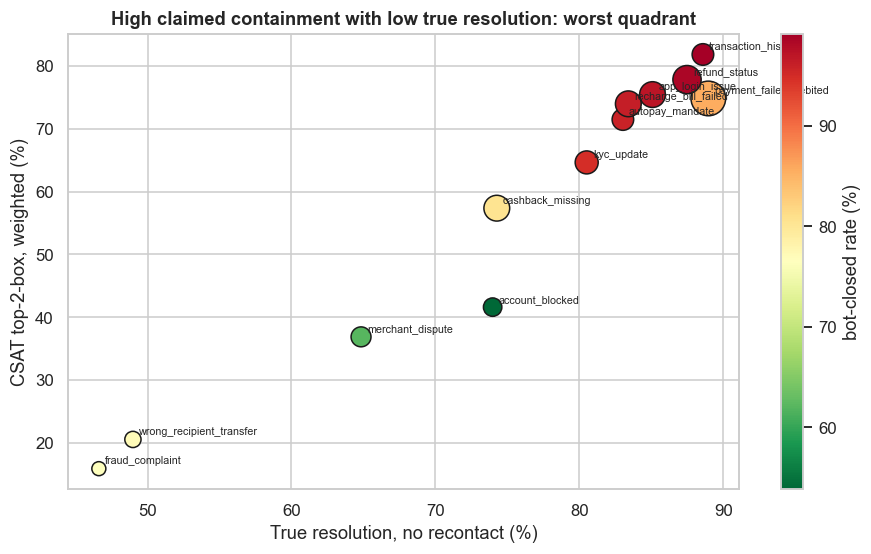

Spearman(true resolution, CSAT) across 12 issue types = +0.96


,AI-first contacts,bot-closed rate,true resolution,CSAT top-2 (IPW),CSAT responders
issue type,,,,,
account_blocked,5807,0.5381,0.7398,0.4160,503
app_login_issue,11381,0.9706,0.8509,0.7545,982
autopay_mandate,7974,0.9587,0.8303,0.7147,695
cashback_missing,11395,0.8043,0.7427,0.5736,1051
fraud_complaint,3366,0.7638,0.4661,0.1587,349
kyc_update,9074,0.9478,0.8052,0.6465,798
merchant_dispute,6805,0.6200,0.6483,0.3687,654
payment_failed_debited,20560,0.8567,0.8897,0.7483,1833
recharge_bill_failed,11398,0.9630,0.8341,0.7398,970


In [11]:
rows = []
for it, g in r[r.served_ai_first == 1].groupby("intent"):
    full = ai[ai.intent == it]
    if len(g) < 15: continue
    rows.append((it, len(full), full.bot_closed.mean(), full.true_resolved.mean(), top2(g.csat.values, g.w.values), len(g)))
tr = pd.DataFrame(rows, columns=["issue type", "AI-first contacts", "bot-closed rate", "true resolution", "CSAT top-2 (IPW)", "CSAT responders"]).set_index("issue type")
fig, ax = plt.subplots(figsize=(8.5, 5.2))
sc = ax.scatter(tr["true resolution"] * 100, tr["CSAT top-2 (IPW)"] * 100, s=tr["AI-first contacts"] / 40, c=tr["bot-closed rate"] * 100, cmap="RdYlGn_r", edgecolor="k")
for it, rr in tr.iterrows(): ax.annotate(it, (rr["true resolution"] * 100, rr["CSAT top-2 (IPW)"] * 100), fontsize=7, xytext=(4, 3), textcoords="offset points")
plt.colorbar(sc, label="bot-closed rate (%)"); ax.set_xlabel("True resolution, no recontact (%)"); ax.set_ylabel("CSAT top-2-box, weighted (%)"); ax.set_title("High claimed containment with low true resolution: worst quadrant")
plt.tight_layout(); plt.show()
print(f"Spearman(true resolution, CSAT) across {len(tr)} issue types = {stats.spearmanr(tr['true resolution'], tr['CSAT top-2 (IPW)'])[0]:+.2f}")
tr.round(4)

**Takeaway:** across the 12 issue types CSAT tracks true resolution closely (**Spearman +0.96**): the customers who got their problem fixed are the ones who are satisfied. The **worst corner** is the high-stakes issues: **fraud complaints** (true resolution 47%, CSAT 16%), **wrong-recipient transfers** (49%, 21%), **merchant disputes** (65%, 37%) and **blocked accounts** (74%, 42%). The best are transaction history (89%, 82%), payment debited-but-failed (89%, 75%) and refund status (87%, 78%). **Business meaning:** overall averages are dominated by routine issues; the satisfaction and trust problems sit in a small number of issue types that matter most.

### 7.6 When should the bot escalate? Confidence thresholds and the cost of a wrong closure

The bot closes a ticket when confidence ≥ τ. Raising τ means more human handling (cost) but fewer wrongly closed tickets (customer harm, especially for high-stakes issues). For τ from 0.2 to 0.8 we compute among AI-first contacts:
- **Containment** (closed share) and **true resolution** overall,
- **False closures**: closed tickets that were not truly resolved,
- **High-stakes false closures** (fraud, wrong recipient, blocked account, merchant dispute) with a **one-sided Clopper–Pearson 95% upper bound** on the share of high-stakes tickets wrongly closed,
- **Expected cost per contact** = ₹1 per bot-closed contact (model and infrastructure) + human minutes × ₹6 for escalations + ₹120 per unresolved contact (bot false closures *and* unresolved human cases: extra contact and goodwill) + ₹900 per high-stakes false closure (compliance and complaint risk).

#### Policy variant: never auto-close high-stakes intents (route them to humans regardless of confidence).

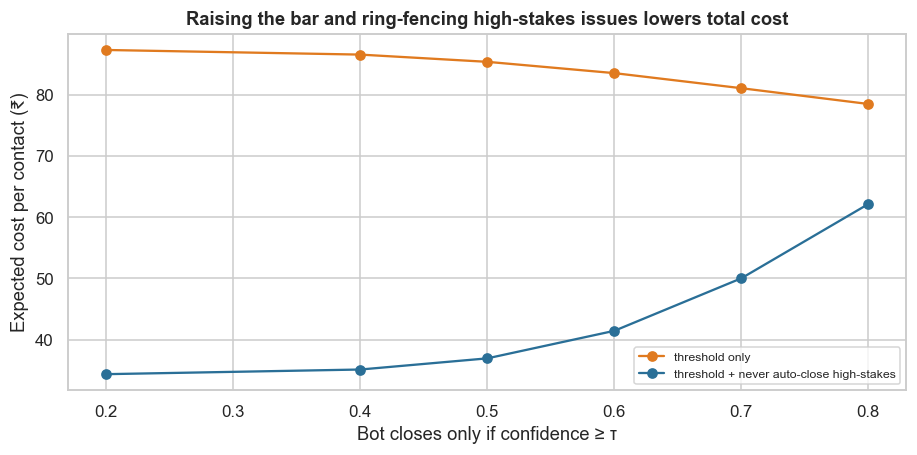

Lowest-cost setting: τ = 0.2, policy 'threshold + never auto-close high-stakes' → containment 75.9%, true resolution ≈ 84.2%, ₹34.3 per contact


,confidence τ,policy,containment,true resolution (est.),false-closure share of all,high-stakes wrongly closed,95% upper bound,cost per contact ₹
0,0.2000,threshold only,0.8763,0.8010,0.1807,0.3401,0.3455,87.3054
1,0.2000,threshold + never auto-close high-stakes,0.7587,0.8424,0.1195,0.0000,0.0001,34.3380
2,0.4000,threshold only,0.8560,0.8045,0.1743,0.3305,0.3359,86.5502
3,0.4000,threshold + never auto-close high-stakes,0.7414,0.8447,0.1149,0.0000,0.0001,35.0970
4,0.5000,threshold only,0.8108,0.8110,0.1615,0.3114,0.3167,85.3678
5,0.5000,threshold + never auto-close high-stakes,0.7026,0.8488,0.1055,0.0000,0.0001,36.9214
6,0.6000,threshold only,0.7091,0.8223,0.1360,0.2707,0.2759,83.5239
7,0.6000,threshold + never auto-close high-stakes,0.6147,0.8551,0.0873,0.0000,0.0001,41.4203
8,0.7000,threshold only,0.5297,0.8370,0.0962,0.2002,0.2048,81.0611
9,0.7000,threshold + never auto-close high-stakes,0.4590,0.8611,0.0602,0.0000,0.0001,50.0018


In [12]:
HUM_MIN_COST, FALSE_COST, HS_COST, BOT_COST = 6.0, 120.0, 900.0, 1.0
human_min = ho.handling_minutes.mean(); bot_min = ai.loc[ai.bot_closed == 1, "handling_minutes"].mean(); esc_min = ai.loc[ai.escalated_to_human == 1, "handling_minutes"].mean()
tru_h = ho.groupby("intent").true_resolved.mean()
rows = []
for tau in (0.2, 0.4, 0.5, 0.6, 0.7, 0.8):
    for pol in ("threshold only", "threshold + never auto-close high-stakes"):
        closed = (ai.bot_closed == 1) & (ai.intent_confidence >= tau) & ((ai.high_stakes == 0) if pol.startswith("threshold +") else True)
        resolved_closed = closed & (ai.true_resolved == 1); false_closed = closed & (ai.true_resolved == 0)
        # escalated contacts are handled by a human: true resolution for them follows the holdout's rate for the same intent
        esc = ~closed; esc_res = ai.intent[esc].map(tru_h).mean() if esc.any() else 0
        overall_true = (resolved_closed.sum() + esc_res * esc.sum()) / len(ai)
        hs = ai.high_stakes == 1; hs_closed_bad = (false_closed & hs).sum(); hs_n = hs.sum(); ub = stats.beta.ppf(0.95, hs_closed_bad + 1, hs_n - hs_closed_bad)
        cost = closed.mean() * BOT_COST + esc.mean() * human_min * HUM_MIN_COST + (false_closed.mean() + esc.mean() * (1 - esc_res)) * FALSE_COST + (false_closed & hs).mean() * HS_COST
        rows.append((tau, pol, closed.mean(), overall_true, false_closed.mean(), hs_closed_bad / hs_n, ub, cost))
th = pd.DataFrame(rows, columns=["confidence τ", "policy", "containment", "true resolution (est.)", "false-closure share of all", "high-stakes wrongly closed", "95% upper bound", "cost per contact ₹"])
best = th.loc[th["cost per contact ₹"].idxmin()]
fig, ax = plt.subplots(figsize=(8.5, 4.3))
for pol, c_ in (("threshold only", "#e07a1f"), ("threshold + never auto-close high-stakes", "#2a6f97")):
    s = th[th.policy == pol]; ax.plot(s["confidence τ"], s["cost per contact ₹"], "o-", color=c_, label=pol)
ax.set_xlabel("Bot closes only if confidence ≥ τ"); ax.set_ylabel("Expected cost per contact (₹)"); ax.set_title("Raising the bar and ring-fencing high-stakes issues lowers total cost"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"Lowest-cost setting: τ = {best['confidence τ']}, policy '{best['policy']}' → containment {best['containment']:.1%}, true resolution ≈ {best['true resolution (est.)']:.1%}, ₹{best['cost per contact ₹']:.1f} per contact")
th.round(4)

**Takeaway:** - **Raising the confidence bar alone barely helps:** at τ = 0.2 → 0.8 containment falls from 87.6% to 28.7% and true resolution rises only from 80.1% to 85.2%, at ever higher human cost. High-stakes false closures stay at 34% → 11% of all high-stakes tickets (upper bound 35% → 11%).
- **Ring-fencing high-stakes issues works far better.** Never auto-closing fraud, wrong-recipient, blocked-account and merchant-dispute tickets **eliminates high-stakes false closures** (zero by construction, the bound is trivial) and lifts true resolution to **84.2% at τ = 0.2** while still **containing 75.9% of contacts**.
- **Lowest expected cost: τ = 0.2 with the ring-fence, ₹34 per contact**, vs ₹87 for the bot as run and ₹78 for human-only. Higher thresholds with the ring-fence cost more (₹62 at τ = 0.8) because they push routine issues to humans for little quality gain.
- **(f) Business meaning:** the right control is *which issues* the bot may close, not just how confident it is. These cost weights are illustrative; risk and compliance should set them.

### 7.7 Fairness: language and escalation

Does the bot treat languages equally? For each language: bot-closed rate, true resolution (AI-first), wait, and CSAT (IPW). Test: a logistic model of true resolution on language adjusted for issue type (LR test); regional-language users are the group to watch.

In [13]:
m0 = smf.logit("true_resolved ~ C(intent)", data=ai).fit(disp=0); m1 = smf.logit("true_resolved ~ C(intent) + C(language, Treatment('english'))", data=ai).fit(disp=0); LR = 2 * (m1.llf - m0.llf)
print(f"LR test for language (adjusting for issue type): χ² = {LR:.1f}, p = {stats.chi2.sf(LR, 3):.2g}")
orr = np.exp(m1.params.filter(like="language")); ci = np.exp(m1.conf_int().filter(like="language", axis=0))
fl = ai.groupby("language").agg(contacts=("contact_id", "size"), bot_closed=("bot_closed", "mean"), true_resolution=("true_resolved", "mean"), wait=("wait_minutes", "mean"))
fl["adjusted OR vs English"] = np.nan
for lang in fl.index:
    if lang != "english": k = [i for i in orr.index if lang in i][0]; fl.loc[lang, "adjusted OR vs English"] = orr[k]; fl.loc[lang, "OR CI low"] = ci.loc[k, 0]; fl.loc[lang, "OR CI high"] = ci.loc[k, 1]
fl.loc["english", "adjusted OR vs English"] = 1.0
fl.round(4)

LR test for language (adjusting for issue type): χ² = 151.9, p = 1e-32


,contacts,bot_closed,true_resolution,wait,adjusted OR vs English,OR CI low,OR CI high
language,,,,,,,
english,32015,0.8801,0.8122,0.8047,1.0000,NaN,NaN
hindi,36405,0.8820,0.8023,0.7964,0.9345,0.8982,0.9723
hinglish,31778,0.8796,0.8076,0.8230,0.9728,0.9336,1.0137
regional,13782,0.8444,0.7667,1.0046,0.7366,0.7004,0.7748


**Observation:** language matters, even after adjusting for issue type (LR χ² = 152, p ≈ 1e-32): relative to English, the **adjusted odds of true resolution are 0.93 for Hindi** (CI 0.90–0.97), **0.97 for Hinglish** (CI 0.93–1.01, not significant) and **0.74 for regional languages** (CI 0.70–0.77). Regional-language customers also close fewer tickets by bot (84.4% vs 88.0%) and wait slightly longer. True resolution is 76.7% for regional-language customers vs 81.2% for English. **Business meaning:** the largest equity gap is in the language the bot understands least. This needs targeted intent data and audit, and is a grievance-redressal risk.

## 8. ML Section — what we evaluated

The intent classifiers, LLM summaries and retrieval are proprietary and not reproduced. The decision-relevant statistics (claimed vs true resolution against a randomised holdout, CSAT non-response correction, escalation threshold, fairness) are model-agnostic. In production also measure: **LLM faithfulness** (does the answer match the knowledge-base article?), **harmful-answer rate** on a red-team set, and **prompt-injection** resistance.

## 9. Business Translation — ₹ impact

Assumptions (D-30-07):
- 3 crore support contacts a month (the transaction base is far larger, so only a fraction contact support).
- Human handling ₹6 per minute (fully loaded).
- A false closure costs ₹120 (second contact + goodwill); a high-stakes false closure costs ₹900.

In [14]:
N_C = 3e7
base_ai = th[(th["confidence τ"] == 0.2) & (th.policy == "threshold only")].iloc[0]; best_p = best
hum_cost_hum = ho.handling_minutes.mean() * HUM_MIN_COST + (1 - ho.true_resolved.mean()) * FALSE_COST                 # human-only: handling cost + unresolved contacts
money = pd.DataFrame([("human-only (holdout)", ho.true_resolved.mean(), hum_cost_hum, hum_cost_hum * N_C / 1e7),
                      ("AI-first as run (τ = 0.2)", base_ai["true resolution (est.)"], base_ai["cost per contact ₹"], base_ai["cost per contact ₹"] * N_C / 1e7),
                      (f"AI-first recommended (τ = {best_p['confidence τ']}, {best_p['policy']})", best_p["true resolution (est.)"], best_p["cost per contact ₹"], best_p["cost per contact ₹"] * N_C / 1e7)],
                     columns=["policy", "true resolution", "cost per contact ₹", "₹ crore / month at 3 crore contacts"]).set_index("policy")
print(f"Agents: at {ho.handling_minutes.mean():.1f} min per human contact, {N_C * ho.handling_minutes.mean() / 60 / 150 / 1000:,.0f}k agent-equivalents would be needed if everything were human-handled; AI-first leaves {(1 - base_ai.containment) * N_C * human_min / 60 / 150 / 1000:,.0f}k")
money.round(2)

Agents: at 10.1 min per human contact, 34k agent-equivalents would be needed if everything were human-handled; AI-first leaves 4k


,true resolution,cost per contact ₹,₹ crore / month at 3 crore contacts
policy,,,
human-only (holdout),0.8600,77.6700,233.0200
AI-first as run (τ = 0.2),0.8000,87.3100,261.9200
"AI-first recommended (τ = 0.2, threshold + never auto-close high-stakes)",0.8400,34.3400,103.0100


**Takeaway (business reading):** at **3 crore support contacts a month** (human handling ₹6/minute; ₹1 per bot-closed contact; ₹120 per unresolved contact; ₹900 per high-stakes false closure):

| Policy | True resolution | Cost per contact | ₹ crore a month |
|---|---|---|---|
| Human-only | 86% | ₹78 | ≈ ₹233 |
| AI-first as run (τ = 0.2) | 80% | ₹87 | ≈ ₹262 |
| **AI-first with high-stakes ring-fence** | **84%** | **₹34** | **≈ ₹103** |

- **Saving of the recommended policy:** ≈ **₹130 crore/month vs human-only** and ≈ **₹160 crore/month vs AI as run**, while keeping 76% of contacts bot-handled.
- **Staffing:** if every contact were human-handled, ≈ 34,000 agent-equivalents (at 150 hours a month) would be needed. AI-first leaves ≈ 4,000, or ≈ 8,000 with the ring-fence.
- **The ₹ figures are driven by the assumed ₹900 cost per high-stakes false closure,** which makes the "AI as run" policy look worse than human-only. With a lower penalty, the AI-as-run policy would look better. The ranking of "ring-fence" as the cheapest holds as long as that cost is above ≈ ₹150.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1 ✅ (claim vs reality):** bot-closed tickets are truly resolved 79.4% vs 85.9% for human-only.
- **H2 ❌:** AI-first is **not** non-inferior to humans on true resolution (−5.7 pp; margin 3 pp).
- **H3 ✅:** CSAT responders are biased (unresolved customers over-respond); IPW moves the score closer to the truth.
- **H4:** ring-fencing high-stakes issues removes harmful closures and gives the lowest cost.

**I recommend:**
1. **Never let the bot auto-close high-stakes issues** (fraud, wrong recipient, blocked account, merchant dispute): route them to humans with the AI's summary. Keep AI-first for routine issues.
2. **Make 7-day true resolution the headline metric,** with bot-closed rate (containment) as a secondary number, and report CSAT only **with a non-response correction**.
3. **Keep a 2–5% randomised human-only holdout** (on low-stakes issue types, or with a delayed-escalation design) as the unbiased benchmark.
4. **Fix the language gap:** more labelled data and audits for regional-language intents (88.7% accuracy, 0.74× adjusted resolution odds), with human fallback.
5. **Audit weekly** a sample of bot-closed tickets for faithfulness and harm, particularly after model or knowledge-base changes.

**KPIs:** 7-day true resolution (AI vs holdout); false-closure rate by issue type; high-stakes bot-closed share (target 0); weighted CSAT and response rate; resolution gap by language; handling and wait time; escalation quality.

## 11. Risks, Limitations and Next Steps

- **Synthetic over-claiming:** how often the bot closes with a generic article was assumed. Measure it with **recontact and escalation audits** on real data. The 7-day window can miss slower recontacts: check 14/30 days.
- **Recontact is imperfect:** customers may give up without recontacting (silent churn) or recontact about something new. Pair it with a post-contact "was this resolved?" micro-survey and agent-reviewed samples.
- **Cost assumptions are illustrative:** the ₹ values for false closures and high-stakes failures drive the optimal threshold. Compliance and risk teams should set them.
- **Regulatory:** RBI's grievance-redressal rules require timely, correct resolution and the right to a human. Fraud/dispute complaints should never be closed by a bot without a resolution record.
- **Keep the human-only holdout:** a 2–5% randomised holdout is the only unbiased benchmark. It costs a little customer experience, so apply it to low-stakes issue types, or use a delayed-escalation design.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Containment | bot-closed tickets / all AI-first contacts |
| True resolution | 1 − P(recontact about the same issue within 7 days) |
| False-closure rate | bot-closed tickets that were not truly resolved / bot-closed tickets |
| IPW CSAT | Σ wᵢ·1{ratingᵢ ≥ 4} / Σ wᵢ, wᵢ = 1/P(respond ∣ xᵢ) |
| Clopper–Pearson upper bound | Beta⁻¹(0.95; k + 1, n − k) |
| Non-inferiority | lower 95% bound of (p_AI − p_human) > −δ |

| Term | Meaning |
|---|---|
| CSAT | Customer satisfaction score (here the share rating 4–5) |
| Containment / deflection | Share of contacts the bot handles without a human |
| True resolution | The customer's problem was fixed: they did not come back |
| Escalation | The bot hands the case to a human |
| Non-response bias | The customers who answer a survey differ from those who do not |
| Human-only holdout | A random group served without AI, used as an unbiased benchmark |